In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (3, 4, 5)  # حالت اولیه پشته‌ها
nodes = 0  # 

In [2]:
# تابع تولید تمام حرکت‌های ممکن از یک وضعیت
def moves(piles, order="small_first"):
    result = []  # لیست حرکات
    for i, n in enumerate(piles):  # بررسی هر پشته
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)  # تعداد سنگ‌های قابل برداشت
        for take in takes:  # امتحان هر تعداد برداشت
            new = list(piles)  # کپی از وضعیت
            new[i] = n - take  # اعمال برداشت
            result.append(tuple(new))  # ذخیره وضعیت جدید
    return result  # 

In [3]:
# الگوریتم Minimax با توسعه Misère
def minimax(piles, player):
    global nodes
    nodes += 1  # افزایش شمارنده گره‌ها
    if sum(piles) == 0:  # شرط پایان بازی
        return 1 if player == "A" else -1  # برنده و بازنده در حالت Misère
    values = [minimax(nxt, "B" if player == "A" else "A") for nxt in moves(piles)]  # بررسی همه حرکات
    return max(values) if player == "A" else min(values)  # انتخاب بهترین مقدار


In [4]:
# الگوریتم Alpha-Beta با هرس شاخه‌ها
def alphabeta(piles, player, alpha, beta, order="small_first"):
    global nodes
    nodes += 1  # افزایش شمارنده گره‌ها
    if sum(piles) == 0:  # شرط پایان بازی
        return 1 if player == "A" else -1  # مقدار پایانی
    if player == "A":  # نوبت بازیکن حداکثرساز
        value = -2  # مقدار اولیه
        for nxt in moves(piles, order):  # بررسی حرکات
            value = max(value, alphabeta(nxt, "B", alpha, beta, order))  # به‌روزرسانی مقدار
            alpha = max(alpha, value)  # به‌روزرسانی آلفا
            if alpha >= beta: break  # هرس کردن
        return value  # برگرداندن بهترین مقدار
    else:  # نوبت بازیکن حداقل‌ساز
        value = 2  # مقدار اولیه
        for nxt in moves(piles, order):  # بررسی حرکات
            value = min(value, alphabeta(nxt, "A", alpha, beta, order))  # به‌روزرسانی مقدار
            beta = min(beta, value)  # به‌روزرسانی بتا
            if alpha >= beta: break  # هرس کردن
        return value  # برگرداندن بهترین مقدار


In [5]:
# پیدا کردن بهترین حرکت برای بازیکن A
def get_best_move(piles, player):
    best_nxt, best_value = None, None  # مقادیر اولیه
    for nxt in moves(piles, "big_first"):  # بررسی حرکات
        value = alphabeta(nxt, "B" if player == "A" else "A", -2, 2, "big_first")  # ارزیابی حرکت
        better = best_value is None or (value > best_value if player == "A" else value < best_value)  # مقایسه
        if better:  # اگر حرکت بهتری پیدا شد
            best_nxt, best_value = nxt, value  # ذخیره آن
    return best_nxt  # 

In [6]:
# شمارش گره‌ها برای مقایسه
nodes = 0; minimax(START, "A"); n_minimax = nodes  # اجرای Minimax
nodes = 0; alphabeta(START, "A", -2, 2, "small_first"); n_ab_natural = nodes  # اجرای Alpha-Beta عادی
nodes = 0; alphabeta(START, "A", -2, 2, "big_first"); n_ab_good = nodes  # اجرای Alpha-Beta هوشمند
print(f"Minimax: {n_minimax} | Alpha-Beta: {n_ab_natural} | Alpha-Beta (Big First): {n_ab_good}\n")
print('[...] running simulation, please wait')

Minimax: 1038768 | Alpha-Beta: 30492 | Alpha-Beta (Big First): 3763

[...] running simulation, please wait


In [7]:

# تولید دیتاست
def generate_dataset(num_games=50):
    rng = np.random.default_rng(42)  # تنظیم تصادفی‌سازی
    rows = []  # لیست داده‌ها
    for _ in range(num_games):  # حلقه اجرای بازی‌ها
        piles = tuple(int(x) for x in rng.integers(1, 6, size=3))  # تولید پشته تصادفی
        global nodes
        nodes = 0; alphabeta(piles, "A", -2, 2, "big_first"); nodes_ab = nodes  # شمارش گره Alpha-Beta
        nodes = 0; minimax(piles, "A"); nodes_mm = nodes  # شمارش گره Minimax
        board, player, n_moves = piles, "A", 0  # مقداردهی اولیه بازی
        while sum(board) > 0:  # تا زمانی که سنگ وجود دارد
            if player == "A": board = get_best_move(board, "A")  # حرکت هوشمند A
            else: board = moves(board)[rng.integers(len(moves(board)))]  # حرکت تصادفی B
            player = "B" if player == "A" else "A"  # تغییر نوبت
            n_moves += 1  # شمارش حرکات
        winner = "B" if player == "A" else "A"  # تعیین برنده
        rows.append({"p1": piles[0], "p2": piles[1], "p3": piles[2], "total": sum(piles), "nim_sum": piles[0] ^ piles[1] ^ piles[2], "nodes_minimax": nodes_mm, "nodes_alphabeta": nodes_ab, "moves": n_moves, "winner": winner})  # ذخیره سطر داده
    return pd.DataFrame(rows)  # برگرداندن دیتافریم


In [8]:
df = generate_dataset()  # ساخت دیتاست
df.to_csv("nim_games.csv", index=False)  # ذخیره در فایل CSV
print(df.head(), "\n")  # 

   p1  p2  p3  total  nim_sum  nodes_minimax  nodes_alphabeta  moves winner
0   1   4   4      9        1          13898              603      4      B
1   3   5   1      9        7          12456              479      4      B
2   2   1   3      6        0            447              171      3      A
3   4   4   4     12        4        1176106              747      4      B
4   3   1   5      9        7          12456              784      4      B 



In [9]:
# بررسی کیفیت داده‌ها و آمار توصیفی
print(df.shape)  # ابعاد دیتاست
print(df.isna().sum().sum())  # تعداد مقادیر گمشده
print(df.duplicated().sum(), "\n")  # تعداد سطرهای تکراری
print(df[["total", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(2), "\n")  # 

(50, 9)
0
5 

       total  nodes_minimax  nodes_alphabeta  moves
count  50.00          50.00            50.00  50.00
mean    9.34      328267.54          2827.24   4.96
std     2.16      809912.18          5086.12   1.28
min     3.00          16.00            12.00   3.00
25%     8.00        4348.00           263.00   4.00
50%    10.00       52637.50           713.00   4.00
75%    11.00      228972.00          3273.00   6.00
max    13.00     4198252.00         22764.00   8.00 



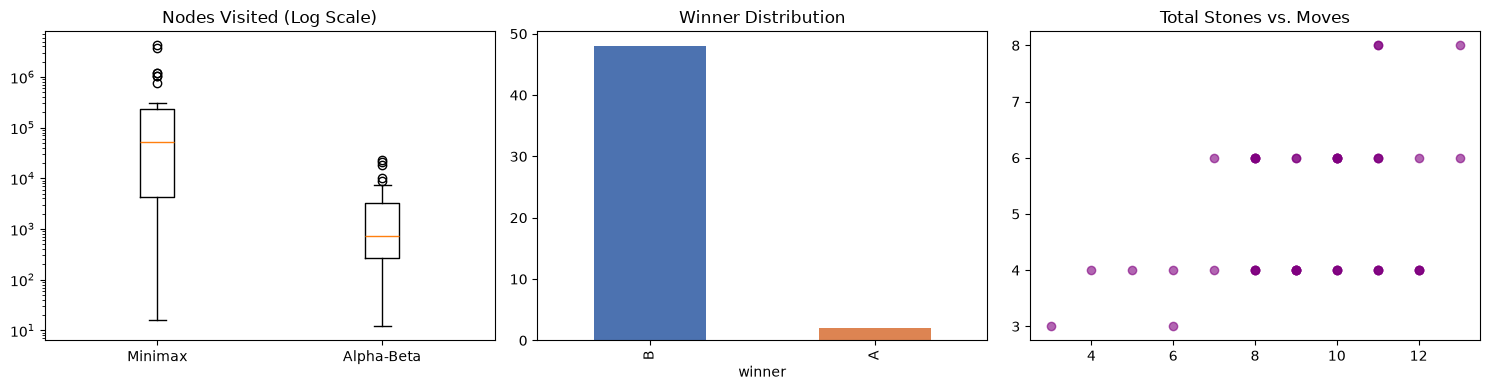

In [10]:

# رسم نمودارهای تحلیلی
fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # ایجاد سه محور نمودار
axes[0].boxplot([df['nodes_minimax'], df['nodes_alphabeta']], tick_labels=['Minimax', 'Alpha-Beta'])  # نمودار باکس‌پلات
axes[0].set_yscale('log')  # مقیاس لگاریتمی
axes[0].set_title('Nodes Visited (Log Scale)')  # عنوان
df['winner'].value_counts().plot(kind='bar', ax=axes[1], color=['#4C72B0', '#DD8452'])  # نمودار برنده‌ها
axes[1].set_title('Winner Distribution')  # عنوان
axes[2].scatter(df['total'], df['moves'], alpha=0.6, color='purple')  # نمودار پراکندگی
axes[2].set_title('Total Stones vs. Moves')  # عنوان
plt.tight_layout()  # تنظیم فاصله‌ها
plt.show()  # نمایش نمودارها


In [11]:
# شبیه‌سازی یک بازی نهایی و چاپ برنده با print
print("--- Final Game Simulation ---")  # چاپ عنوان
final_board = START  # شروع از حالت اولیه
player = "A"  # شروع با بازیکن A
print(f"Initial state: {final_board}")  # چاپ وضعیت اولیه
while sum(final_board) > 0:  # تا پایان بازی
    if player == "A": 
        final_board = get_best_move(final_board, "A")  # حرکت هوشمند A
    else: 
        final_board = moves(final_board)[0]  # حرکت ساده B
    print(f"Player {player} moved. Board: {final_board}")  # چاپ وضعیت بعد از هر حرکت
    player = "B" if player == "A" else "A"  # تغییر نوبت
print(f"Game Over! Winner: {'B' if player == 'A' else 'A'}")  # چاپ برنده نهایی


--- Final Game Simulation ---
Initial state: (3, 4, 5)
Player A moved. Board: (1, 4, 5)
Player B moved. Board: (0, 4, 5)
Player A moved. Board: (0, 4, 4)
Player B moved. Board: (0, 3, 4)
Player A moved. Board: (0, 3, 3)
Player B moved. Board: (0, 2, 3)
Player A moved. Board: (0, 2, 2)
Player B moved. Board: (0, 1, 2)
Player A moved. Board: (0, 1, 0)
Player B moved. Board: (0, 0, 0)
Game Over! Winner: B
